# CXC 201

In [7]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

load_dotenv()

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
    
from src.utils import (
    generate_confusion, 
    generate_roc_curve, 
    plot_train_accuracy, 
    plot_train_loss, 
    get_dataset_distribution
)


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC201"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data04", "train")
test_data_dir = os.path.join(dataset_path, "data04", "test")
val_data_dir = os.path.join(dataset_path, "data04", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data04/train
/Users/joshan/Documents/final-year-project/dataset/data04/test
/Users/joshan/Documents/final-year-project/dataset/data04/val


In [9]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     6083 │        6165 │           5924 │      1155 │   19327 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 6083,
  'PNEUMONIA': 6165,
  'TUBERCULOSIS': 5924,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [10]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode='rgb',
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 19326 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


In [11]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


In [12]:
base_model = InceptionV3(
    input_shape=(224,224, 3), 
    weights='imagenet', 
    include_top=False # remove last layer of vgg16
)

In [13]:
# don't want to train existing layers 
base_model.trainable = False

In [16]:
data_augmentation = models.Sequential([
    
    # Flip left-right (lungs are symmetric)
    layers.RandomFlip("horizontal"),
    
    # Small rotation for positioning differences
    layers.RandomRotation(0.05),
    
    # Slight zoom to simulate distance from scanner
    layers.RandomZoom(0.1),
    
    # Small translation for patient positioning
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    
    # Slight contrast variation from different scanners
    layers.RandomContrast(0.1),
    
])


2026-05-31 14:11:47.446375: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


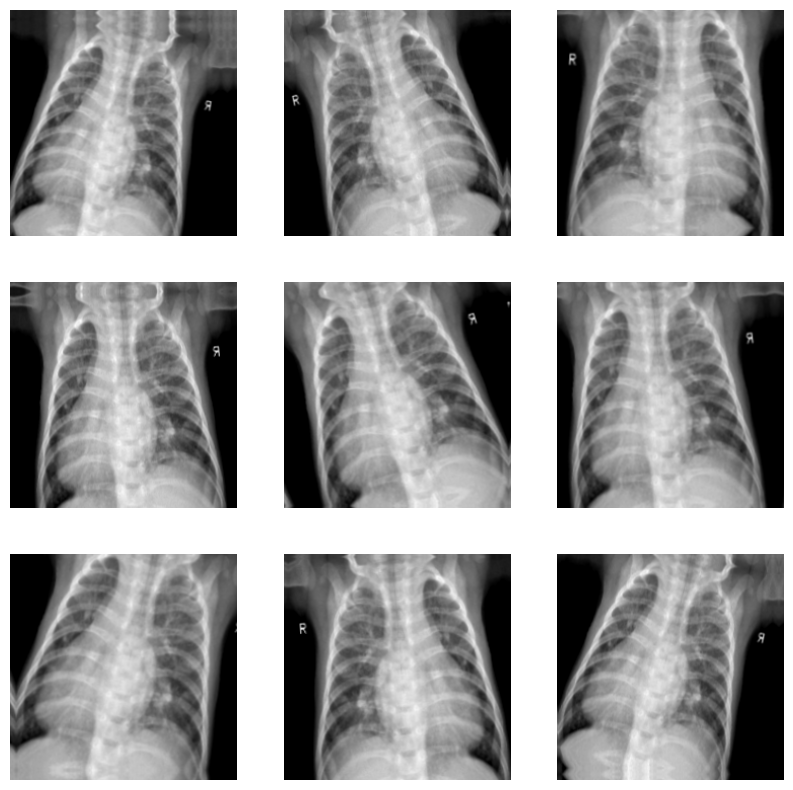

In [17]:
import matplotlib.pyplot as plt

for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

In [11]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    
    layers.Lambda(preprocess_input),
    
    base_model,
    
    layers.GlobalAveragePooling2D(),
   

    layers.Dense(
        256,
        activation='relu',
    ),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    layers.Dense(4, activation='softmax')
])

In [12]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


model.summary()


# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_94          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,329,380 (85.18 MB)

 Trainable params: 526,084 (2.01 MB)

 Non-trainable params: 21,803,296 (83.17 MB)

Epoch 1/10


2026-05-30 16:47:46.468066: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


604/604 ━━━━━━━━━━━━━━━━━━━━ 136s 216ms/step - accuracy: 0.8433 - loss: 0.4359 - val_accuracy: 0.8804 - val_loss: 0.2870
Epoch 2/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 118s 196ms/step - accuracy: 0.8845 - loss: 0.2989 - val_accuracy: 0.8896 - val_loss: 0.3014
Epoch 3/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 143s 236ms/step - accuracy: 0.8910 - loss: 0.2771 - val_accuracy: 0.9014 - val_loss: 0.2415
Epoch 4/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 150s 247ms/step - accuracy: 0.8982 - loss: 0.2620 - val_accuracy: 0.9067 - val_loss: 0.2552
Epoch 5/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 143s 236ms/step - accuracy: 0.8983 - loss: 0.2557 - val_accuracy: 0.9146 - val_loss: 0.2410
Epoch 6/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 118s 196ms/step - accuracy: 0.8995 - loss: 0.2528 - val_accuracy: 0.9212 - val_loss: 0.2219
Epoch 7/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 119s 196ms/step - accuracy: 0.9003 - loss: 0.2462 - val_accuracy: 0.9067 - val_loss: 0.2182
Epoch 8/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 119s 196ms/step - accuracy: 0.9020 - loss: 0.24

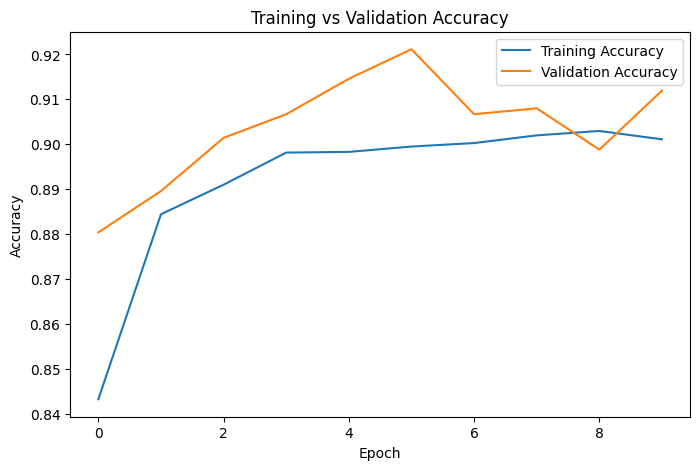

In [13]:
plot_train_accuracy(history=history)

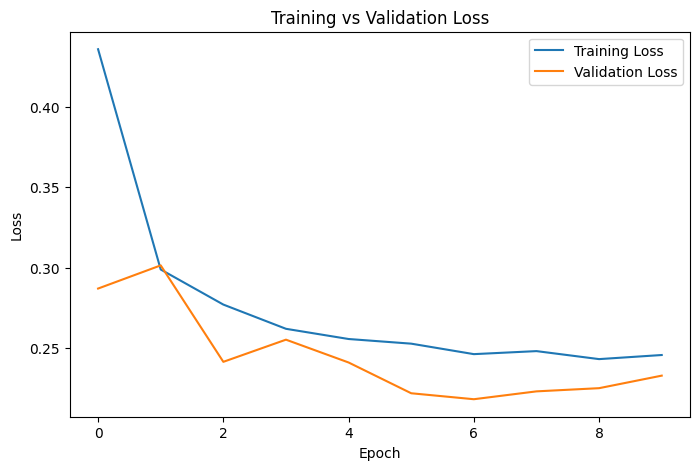

In [14]:
plot_train_loss(history=history)

In [ ]:
# Save the model
model.save('CXC201.keras')
print("Model saved successfully!")

Model saved successfully!


In [14]:
model = tf.keras.models.load_model(
    os.path.join(model_path, MODEL_NAME+".keras"),
    custom_objects={"preprocess_input": preprocess_input}
)

In [15]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

2026-05-31 18:54:08.862138: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 176ms/step - accuracy: 0.8946 - loss: 0.2666
Test Loss: 0.26662659645080566
Test Accuracy: 89.46%


In [16]:
# Evaludate against val data
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 184ms/step - accuracy: 0.9120 - loss: 0.2329
Test Loss: 0.2328689843416214
Test Accuracy: 91.20%


2026-05-31 18:54:55.340016: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


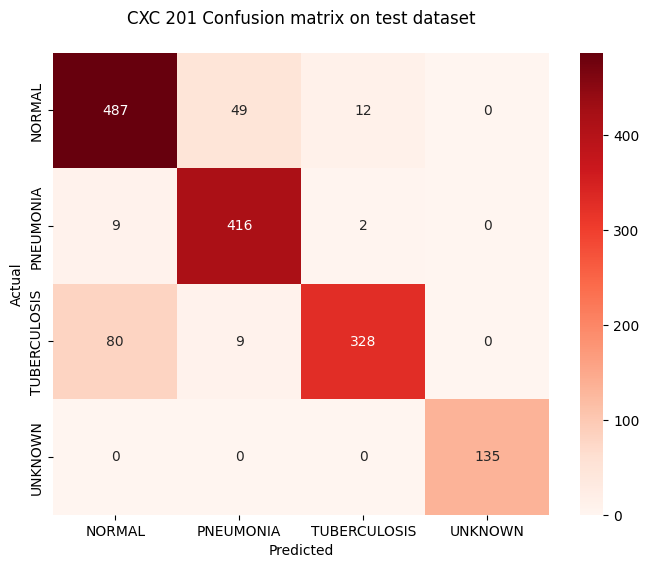

              precision    recall  f1-score   support

      NORMAL       0.85      0.89      0.87       548
   PNEUMONIA       0.88      0.97      0.92       427
TUBERCULOSIS       0.96      0.79      0.86       417
     UNKNOWN       1.00      1.00      1.00       135

    accuracy                           0.89      1527
   macro avg       0.92      0.91      0.91      1527
weighted avg       0.90      0.89      0.89      1527



In [17]:
generate_confusion(test_ds, model=model, title="CXC 201 Confusion matrix on test dataset")

2026-05-31 18:55:04.356179: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


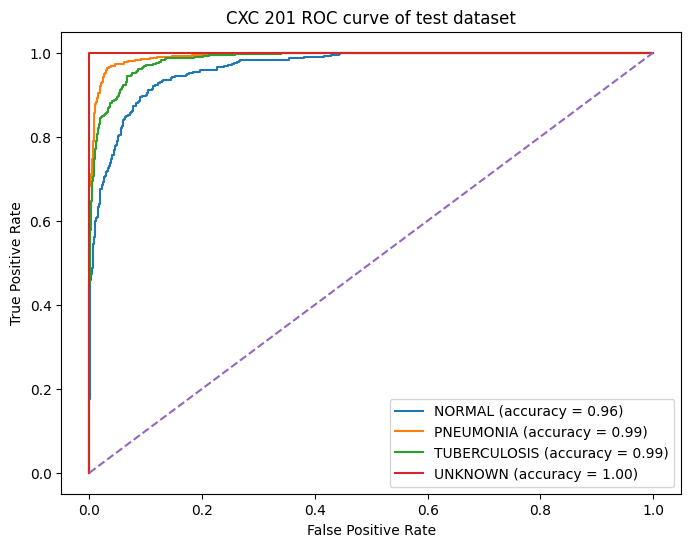

In [18]:
generate_roc_curve(test_ds, model=model, title="CXC 201 ROC curve of test dataset")

2026-05-31 18:55:09.736598: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


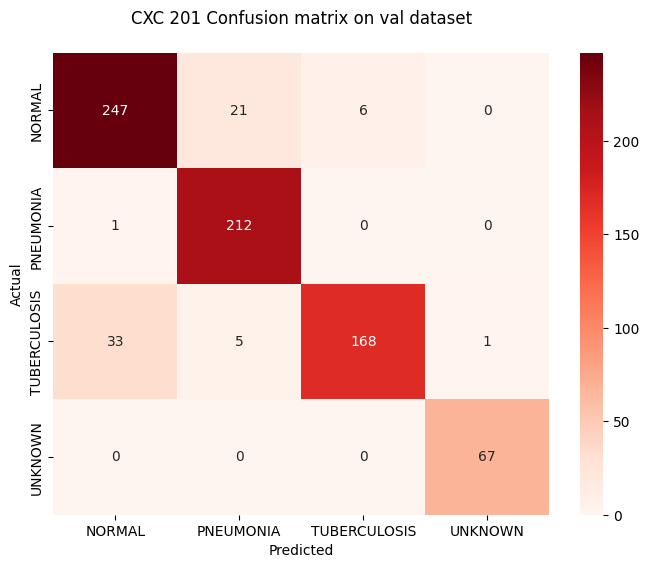

              precision    recall  f1-score   support

      NORMAL       0.88      0.90      0.89       274
   PNEUMONIA       0.89      1.00      0.94       213
TUBERCULOSIS       0.97      0.81      0.88       207
     UNKNOWN       0.99      1.00      0.99        67

    accuracy                           0.91       761
   macro avg       0.93      0.93      0.93       761
weighted avg       0.92      0.91      0.91       761



In [19]:
generate_confusion(val_ds, model=model, title="CXC 201 Confusion matrix on val dataset")

2026-05-31 18:55:14.521309: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


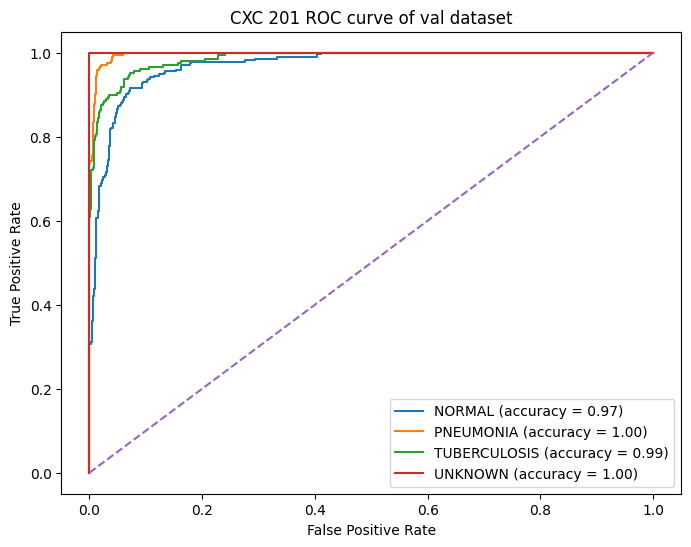

In [20]:
generate_roc_curve(val_ds, model=model, title="CXC 201 ROC curve of val dataset")